# Random Forest — Hyperparameter Tuning

Loads the shared train/val/test splits saved by `data_eda.ipynb`, vectorizes with TF-IDF (update the
config below if `bow_vs_tfidf.ipynb` found a better one than the default), then grid-searches
Random Forest's key hyperparameters. Every candidate combination is logged to MLflow, and the best model
gets registered.

Run `data_eda.ipynb` first — this notebook depends on the CSVs it saves.

In [1]:
# ── libraries ──
import os
import time
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient

/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ── config + load the shared splits ──
MODEL_NAME = "RandomForest"
SEED = 42

DATA_DIR = "../data/processed"
RESULTS_DIR = "results"
MODELS_DIR = "saved_models"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

MLFLOW_EXPERIMENT = "IndianFinSentiment_ClassicalML"
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment(MLFLOW_EXPERIMENT)

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")
print(f"Train: {len(train_df)}  |  Val: {len(val_df)}  |  Test: {len(test_df)}")

Train: 7094  |  Val: 946  |  Test: 1419


## Vectorize with TF-IDF

**Update these two values** if `bow_vs_tfidf.ipynb` found a better config than this default.

In [3]:
TFIDF_MAX_FEATURES = 15_000
TFIDF_NGRAM_RANGE = (1, 2)

vectorizer = TfidfVectorizer(max_features=TFIDF_MAX_FEATURES, ngram_range=TFIDF_NGRAM_RANGE, min_df=2)
X_train = vectorizer.fit_transform(train_df["text"])
X_val = vectorizer.transform(val_df["text"])
X_test = vectorizer.transform(test_df["text"])

y_train, y_val, y_test = train_df["label_id"], val_df["label_id"], test_df["label_id"]
print(f"TF-IDF matrix shape: {X_train.shape}")

TF-IDF matrix shape: (7094, 11720)


In [4]:
def evaluate(y_true, y_pred):
    per_class = f1_score(y_true, y_pred, average=None, labels=[0, 1, 2])
    return {
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "f1_weighted": round(f1_score(y_true, y_pred, average="weighted"), 4),
        "f1_positive": round(per_class[0], 4),
        "f1_neutral": round(per_class[1], 4),
        "f1_negative": round(per_class[2], 4),
    }


def plot_confusion_matrix(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1)[:, None]
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm_pct, annot=True, fmt=".1%", cmap="Blues",
                xticklabels=["positive", "neutral", "negative"],
                yticklabels=["positive", "neutral", "negative"], ax=ax)
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    path = f"{RESULTS_DIR}/cm_{name.lower().replace(' ', '_')}.png"
    plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()
    return path

## Broader hyperparameter search

The old version only searched `n_estimators` (2 values) x `max_depth` (3 values) — 6 candidates
x 3-fold CV = 18 fits. This version adds `min_samples_split`, `min_samples_leaf`, `max_features`,
and `class_weight` (`None` / `"balanced"` / `"balanced_subsample"`), searched with
`RandomizedSearchCV` (the full grid here is 4x4x3x3x3x3 = 1,296 combinations — a full grid at
5-fold CV would be 6,480 fits) and `verbose=2` so every fold's fit prints as it happens.

`n_estimators` is fixed at a moderate 200 for this structural search — the actual tree count gets
tuned properly in the next section via incremental growth + early stopping, which is a much more
direct way to find the right number of trees than including it as just another grid value.

In [5]:
model = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)

param_distributions = {
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", None],
    "class_weight": [None, "balanced", "balanced_subsample"],
}

start = time.time()
random_search = RandomizedSearchCV(
    model, param_distributions, n_iter=30, cv=5, scoring="f1_weighted",
    n_jobs=-1, random_state=SEED, verbose=2,
)
random_search.fit(X_train, y_train)
search_time = time.time() - start

n_combos = len(random_search.cv_results_["params"])
print(f"\nRandom search done in {search_time:.1f}s — tried {n_combos} combinations x 5-fold CV = {n_combos * 5} fits")
print(f"Best params: {random_search.best_params_}")
print(f"Best CV F1 (weighted): {random_search.best_score_:.4f}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits



Random search done in 546.3s — tried 30 combinations x 5-fold CV = 150 fits
Best params: {'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': None, 'class_weight': 'balanced'}
Best CV F1 (weighted): 0.7911


## Log every candidate combination to MLflow

In [6]:
for params, mean_score, std_score in zip(
    random_search.cv_results_["params"],
    random_search.cv_results_["mean_test_score"],
    random_search.cv_results_["std_test_score"],
):
    run_name = f"{MODEL_NAME}_" + "_".join(f"{k}={v}" for k, v in params.items())
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params(params)
        mlflow.log_metric("cv_f1_weighted_mean", round(float(mean_score), 4))
        mlflow.log_metric("cv_f1_weighted_std", round(float(std_score), 4))

print(f"Logged {len(random_search.cv_results_['params'])} candidate runs to MLflow.")

Logged 30 candidate runs to MLflow.


## Overfitting check: train vs val vs test (CV-best structural params, 200 trees)

In [7]:
cv_best_model = random_search.best_estimator_
train_metrics_cv = evaluate(y_train, cv_best_model.predict(X_train))
val_metrics_cv = evaluate(y_val, cv_best_model.predict(X_val))
test_metrics_cv = evaluate(y_test, cv_best_model.predict(X_test))

print(f"{'Split':<8} {'Accuracy':>10} {'F1 (weighted)':>14}")
for name, m in [("Train", train_metrics_cv), ("Val", val_metrics_cv), ("Test", test_metrics_cv)]:
    print(f"{name:<8} {m['accuracy']:>10.4f} {m['f1_weighted']:>14.4f}")

gap = train_metrics_cv["f1_weighted"] - val_metrics_cv["f1_weighted"]
print(f"\nTrain-Val F1 gap: {gap:.4f} (large positive gap = overfitting; random forests trained on")
print("bagged, fairly deep trees will usually show a bigger train-val gap than linear models —")
print("that's normal and doesn't necessarily mean the val/test performance is bad.)")

Split      Accuracy  F1 (weighted)
Train        0.9999         0.9999
Val          0.7865         0.7865
Test         0.7886         0.7886

Train-Val F1 gap: 0.2134 (large positive gap = overfitting; random forests trained on
bagged, fairly deep trees will usually show a bigger train-val gap than linear models —
that's normal and doesn't necessarily mean the val/test performance is bad.)


## "Epoch"-based training: incremental tree growth with early stopping

Random forests don't have `partial_fit`, but `warm_start=True` lets us grow the forest in
increments — add a batch of trees, re-evaluate on val, keep adding while it helps, stop once it
doesn't. Each increment (20 trees here) is the closest analogue to an "epoch" for a forest:
model capacity increases a step at a time and we watch validation performance after each step.
Also tracks the **OOB (out-of-bag) score** — since each tree only sees ~63% of the training rows
(bootstrap sampling), the remaining ~37% work as a free internal validation set per tree, giving
a second, independent overfitting signal alongside val F1.

 Trees | train_acc  train_f1 |   val_acc    val_f1 |  test_acc   test_f1 |     oob
--------------------------------------------------------------------------------------


/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/ensemble/_forest.py:843: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(


/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/ensemble/_forest.py:843: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(


    20 |    0.9968    0.9968 |    0.7717    0.7720 |    0.7611    0.7602 |  0.7240


    40 |    0.9992    0.9992 |    0.7907    0.7909 |    0.7752    0.7745 |  0.7502


...

   200 |    0.9999    0.9999 |    0.7865    0.7865 |    0.7886    0.7886 |  0.7948


/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/ensemble/_forest.py:843: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(


   220 |    0.9999    0.9999 |    0.7907    0.7909 |    0.7872    0.7869 |  0.7960


/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/ensemble/_forest.py:843: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(


   240 |    0.9999    0.9999 |    0.7875    0.7877 |    0.7914    0.7912 |  0.7969

Early stopping: no val F1 improvement for 5 steps (best was 140 trees, val_f1=0.7919)


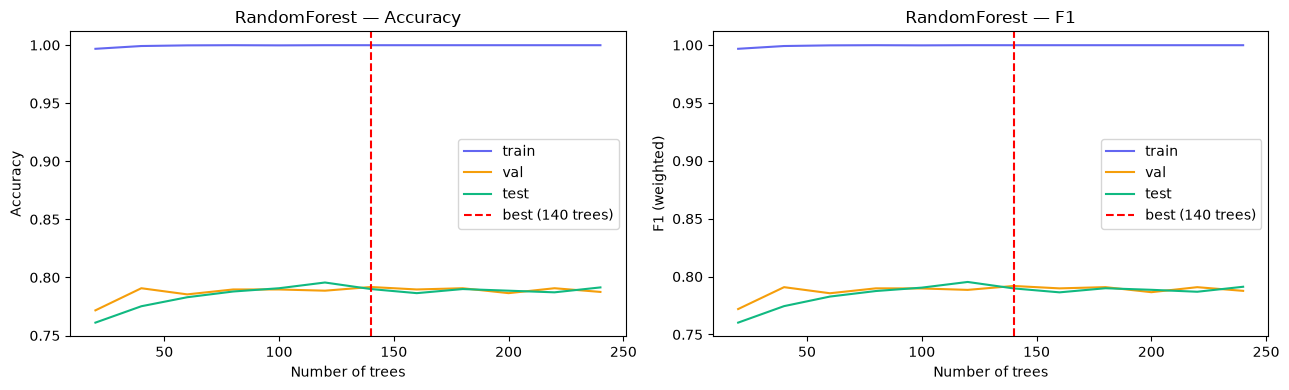

In [8]:
best_struct_params = {k: v for k, v in random_search.best_params_.items()}

MAX_TREES = 2000
TREES_PER_STEP = 20
PATIENCE = 5   # in units of "steps" (each step = +20 trees), so 5 steps = 100 trees of no improvement

warm_model = RandomForestClassifier(
    n_estimators=TREES_PER_STEP, warm_start=True, oob_score=True, bootstrap=True,
    random_state=SEED, n_jobs=-1, **best_struct_params,
)

best_val_f1, best_n_estimators, steps_no_improve = -1.0, 0, 0
best_model_state = None
history = []

print(f"{'Trees':>6} | {'train_acc':>9} {'train_f1':>9} | {'val_acc':>9} {'val_f1':>9} | "
      f"{'test_acc':>9} {'test_f1':>9} | {'oob':>7}")
print("-" * 86)
step = 0
while warm_model.n_estimators <= MAX_TREES:
    step += 1
    warm_model.fit(X_train, y_train)

    train_pred = warm_model.predict(X_train)
    val_pred = warm_model.predict(X_val)
    test_pred = warm_model.predict(X_test)   # informational only — never used to pick the step

    train_acc = accuracy_score(y_train, train_pred)
    train_f1 = f1_score(y_train, train_pred, average="weighted")
    val_acc = accuracy_score(y_val, val_pred)
    val_f1 = f1_score(y_val, val_pred, average="weighted")
    test_acc = accuracy_score(y_test, test_pred)
    test_f1 = f1_score(y_test, test_pred, average="weighted")
    history.append({
        "n_estimators": warm_model.n_estimators, "train_acc": train_acc, "train_f1": train_f1,
        "val_acc": val_acc, "val_f1": val_f1, "test_acc": test_acc, "test_f1": test_f1,
        "oob_score": warm_model.oob_score_,
    })

    print(f"{warm_model.n_estimators:>6} | {train_acc:>9.4f} {train_f1:>9.4f} | "
          f"{val_acc:>9.4f} {val_f1:>9.4f} | {test_acc:>9.4f} {test_f1:>9.4f} | {warm_model.oob_score_:>7.4f}")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_n_estimators = warm_model.n_estimators
        best_model_state = {"estimators": list(warm_model.estimators_)}
        steps_no_improve = 0
    else:
        steps_no_improve += 1
        if steps_no_improve >= PATIENCE:
            print(f"\nEarly stopping: no val F1 improvement for {PATIENCE} steps "
                  f"(best was {best_n_estimators} trees, val_f1={best_val_f1:.4f})")
            break

    warm_model.n_estimators += TREES_PER_STEP

# restore the forest to its best-performing size (drop any trees added after the best point)
warm_model.estimators_ = best_model_state["estimators"]
warm_model.n_estimators = best_n_estimators
history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df["n_estimators"], history_df["train_acc"], label="train", color="#6366f1")
axes[0].plot(history_df["n_estimators"], history_df["val_acc"], label="val", color="#f59e0b")
axes[0].plot(history_df["n_estimators"], history_df["test_acc"], label="test", color="#10b981")
axes[0].axvline(best_n_estimators, color="red", linestyle="--", label=f"best ({best_n_estimators} trees)")
axes[0].set_xlabel("Number of trees"); axes[0].set_ylabel("Accuracy")
axes[0].set_title(f"{MODEL_NAME} — Accuracy"); axes[0].legend()

axes[1].plot(history_df["n_estimators"], history_df["train_f1"], label="train", color="#6366f1")
axes[1].plot(history_df["n_estimators"], history_df["val_f1"], label="val", color="#f59e0b")
axes[1].plot(history_df["n_estimators"], history_df["test_f1"], label="test", color="#10b981")
axes[1].axvline(best_n_estimators, color="red", linestyle="--", label=f"best ({best_n_estimators} trees)")
axes[1].set_xlabel("Number of trees"); axes[1].set_ylabel("F1 (weighted)")
axes[1].set_title(f"{MODEL_NAME} — F1"); axes[1].legend()

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/training_curve_{MODEL_NAME.lower()}.png", dpi=120, bbox_inches="tight")
plt.show()

In [9]:
# ── the incrementally-grown model (best hyperparameters, trained epoch-by-epoch with early
# stopping on tree count) is the final model — always. CV-best (fixed 200 trees, one-shot) is
# kept as an informational reference point only. ──
warm_test_metrics = evaluate(y_test, warm_model.predict(X_test))

print(f"{'Model':<28} {'F1 (weighted)':>14} {'Accuracy':>10}")
print("-" * 54)
print(f"{'CV-best (200 trees, one-shot)':<28} {test_metrics_cv['f1_weighted']:>14.4f} {test_metrics_cv['accuracy']:>10.4f}")
print(f"{'Incremental (' + str(best_n_estimators) + ' trees)':<28} {warm_test_metrics['f1_weighted']:>14.4f} {warm_test_metrics['accuracy']:>10.4f}")

final_model, final_variant, final_test_metrics = warm_model, f"Incremental_{best_n_estimators}trees", warm_test_metrics
print(f"\nFinal model (epoch-trained, best hyperparameters): {MODEL_NAME} ({final_variant})")

Model                         F1 (weighted)   Accuracy
------------------------------------------------------
CV-best (200 trees, one-shot)         0.7886     0.7886
Incremental (140 trees)              0.7898     0.7900

Final model (epoch-trained, best hyperparameters): RandomForest (Incremental_140trees)


## Evaluate the best model on the held-out test set

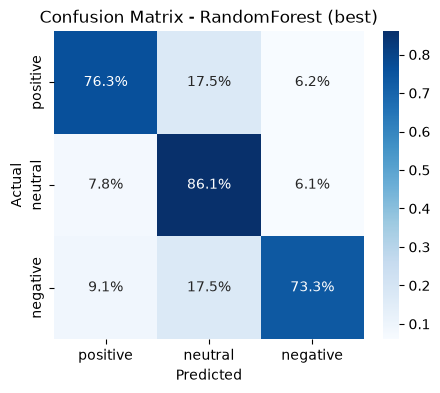

2026/07/19 17:07:52 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



RandomForest (Incremental_140trees) — TEST RESULTS
              precision    recall  f1-score   support

    positive       0.83      0.76      0.80       503
     neutral       0.73      0.86      0.79       511
    negative       0.83      0.73      0.78       405

    accuracy                           0.79      1419
   macro avg       0.80      0.79      0.79      1419
weighted avg       0.80      0.79      0.79      1419



In [10]:
test_preds = final_model.predict(X_test)
test_metrics = evaluate(y_test, test_preds)

with mlflow.start_run(run_name=f"{MODEL_NAME}_BEST_{final_variant}"):
    mlflow.log_params({"variant": final_variant, **best_struct_params})
    mlflow.log_param("n_estimators", final_model.n_estimators)
    mlflow.log_param("tfidf_max_features", TFIDF_MAX_FEATURES)
    mlflow.log_param("tfidf_ngram_range", str(TFIDF_NGRAM_RANGE))
    mlflow.log_metrics(test_metrics)
    mlflow.log_metric("search_time_seconds", round(search_time, 2))

    cm_path = plot_confusion_matrix(y_test, test_preds, f"{MODEL_NAME} (best)")
    mlflow.log_artifact(cm_path)
    mlflow.sklearn.log_model(final_model, "model")
    run_id = mlflow.active_run().info.run_id

print(f"\n{MODEL_NAME} ({final_variant}) — TEST RESULTS")
print(classification_report(y_test, test_preds, target_names=["positive", "neutral", "negative"]))

with open(f"{MODELS_DIR}/{MODEL_NAME.lower()}_best.pkl", "wb") as f:
    pickle.dump({"vectorizer": vectorizer, "model": final_model, "variant": final_variant}, f)

## Register the best model in the MLflow Model Registry

In [11]:
client = MlflowClient()
try:
    registered = mlflow.register_model(model_uri=f"runs:/{run_id}/model", name=f"{MODEL_NAME}_Classifier")
    print(f"Registered '{MODEL_NAME}_Classifier' version {registered.version}")
except Exception as e:
    print(f"Registration skipped/failed: {e}")

print(f"\nBest {MODEL_NAME} test F1 (weighted): {test_metrics['f1_weighted']:.4f}")

Registered model 'RandomForest_Classifier' already exists. Creating a new version of this model...
2026/07/19 17:08:27 WARNING mlflow.tracking._model_registry.fluent: Run with id 519f40c162e9405ebec8ebd96d99814b has no artifacts at artifact path 'model', registering model based on models:/m-42e86fe6fd4e41a0a9db3213ec988263 instead


Registered 'RandomForest_Classifier' version 3

Best RandomForest test F1 (weighted): 0.7898


Created version '3' of model 'RandomForest_Classifier'.
